In [172]:
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf

In [385]:
pip freeze > requirements.txt

# **Data Loading**

In [173]:
data = pd.read_csv("train-test.csv")

# **Data Exploration**

In [174]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [175]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [176]:
data['equipment'].value_counts()

,count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


In [177]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [178]:
data['pickup'].value_counts()

,count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
...,...
Detroit,337
Washington,337
St. Louis,318


KeyboardInterrupt: 

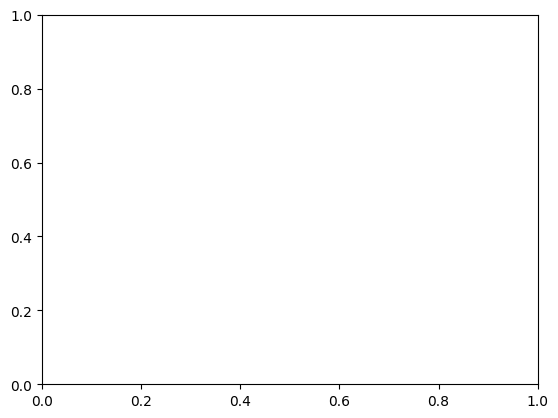

In [10]:
sns.lineplot(data = data,x = 'weight',y ='posted_rate')
plt.show()

In [179]:
data[data["weight"] < 0]["weight"].describe()

,weight
count,292.000000
mean,-31724.195205
std,8262.536326
min,-47500.000000
25%,-37284.250000
50%,-31821.500000
75%,-25928.500000
max,-5000.000000


In [180]:
data["weight"].value_counts().sort_index().head(20)

,count
weight,
-47500.0,13
-46334.0,1
-46187.0,1
-45975.0,1
-45588.0,1
-45221.0,1
-45128.0,1
-44754.0,1
-44572.0,1


In [181]:
(data["weight"] < 0).sum()

np.int64(292)

In [182]:
data[data["weight"] < 0][
    ["pickup", "delivery", "weight", "distance","market_index",	"quote_signal", "posted_rate","equipment"]
].head(30)

,pickup,delivery,weight,distance,market_index,quote_signal,posted_rate,equipment
68,Amarillo,Dayton,-36559.0,1334.2,0.96102,2.11777,2831.27,Reefer
204,Fresno,Tucson,-26670.0,496.2,0.96903,2.13155,1046.92,Dry Van
206,Columbia,Raleigh,-20003.0,411.3,0.94800,2.31682,959.15,Reefer
225,Greensboro,Lubbock,-23981.0,1317.4,1.00820,2.13918,2836.00,Reefer
376,Madison,Providence,-41397.0,1331.1,0.94787,1.91867,2522.54,Dry Van
446,Albuquerque,Albany,-37215.0,2438.3,0.96575,1.96959,4841.57,Reefer
495,Montgomery,Dayton,-31214.0,715.9,0.85153,2.03947,1473.78,Dry Van
641,Tulsa,Indianapolis,-41023.0,582.4,0.81988,2.22721,1264.33,Dry Van
806,Cincinnati,Buffalo,-28320.0,676.1,0.79158,1.95680,1307.76,Dry Van
1093,Cincinnati,Albany,-25153.0,1058.5,0.89891,1.81081,1907.83,Dry Van


In [183]:
data[["posted_rate", "weight", "distance",
    "market_index", "quote_signal", "pickup_lon","pickup_lat","delivery_lon","delivery_lat"]].corr()["posted_rate"].sort_values()

,posted_rate
delivery_lon,-0.257086
pickup_lon,-0.255058
delivery_lat,-0.091970
pickup_lat,-0.090873
quote_signal,-0.039858
market_index,0.034165
weight,0.034840
distance,0.908519
posted_rate,1.000000


# **Feature Engineering & Data cleaning**

In [184]:
data["date"] = pd.to_datetime(data["date"])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       48000 non-null  object        
 1   pickup        48000 non-null  object        
 2   delivery      48000 non-null  object        
 3   pickup_lat    48000 non-null  float64       
 4   pickup_lon    48000 non-null  float64       
 5   delivery_lat  48000 non-null  float64       
 6   delivery_lon  48000 non-null  float64       
 7   distance      48000 non-null  float64       
 8   equipment     48000 non-null  object        
 9   weight        47700 non-null  float64       
 10  date          48000 non-null  datetime64[ns]
 11  market_index  47626 non-null  float64       
 12  quote_signal  48000 non-null  float64       
 13  posted_rate   48000 non-null  float64       
dtypes: datetime64[ns](1), float64(9), object(4)
memory usage: 5.1+ MB


In [185]:
data = data.drop(data[data["weight"]<0].index)

In [186]:
data = pd.get_dummies(data, columns=["equipment"])

In [187]:
data = data.drop('load_id',axis = 1)

### 09-08-2026: A bit of more feature engineering and exploration, as i noticed posted rate is very close to distance x market index x quote signal.

In [188]:
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']

In [189]:
correlation = data[['posted_rate', 'base_rate']].corr().iloc[0, 1]
print(f"Correlation between my formula and posted rate: {correlation:.4f}")

Correlation between my formula and posted rate: 0.8669


In [190]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date'],axis = 1)
data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)

Text(0, 0.5, 'Actual Posted Rate')

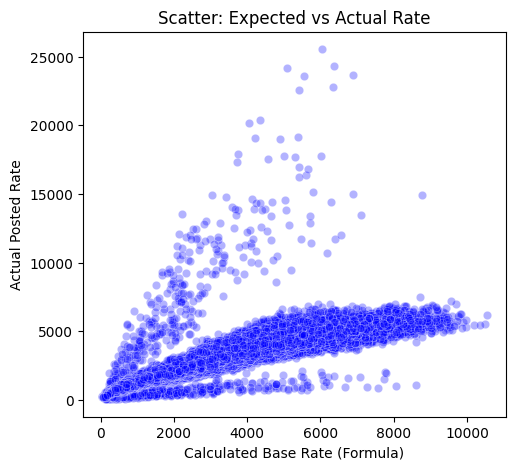

In [191]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=data, x='base_rate', y='posted_rate', alpha=0.3, color='blue')
plt.title("Scatter: Expected vs Actual Rate")
plt.xlabel("Calculated Base Rate (Formula)")
plt.ylabel("Actual Posted Rate")

In [192]:
Q1 = data['posted_rate'].quantile(0.25)
Q3 = data['posted_rate'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data['posted_rate'] < lower_bound) | (data['posted_rate'] > upper_bound)]

print(f"--- Outlier Detection Results ---")
print(f"Total rows in dataset: {len(data)}")
print(f"Upper limit boundary: ${upper_bound:.2f}")
print(f"Total outliers found: {len(outliers)}")
print(f"Percentage of dataset: {(len(outliers) / len(data)) * 100:.2f}%")

--- Outlier Detection Results ---
Total rows in dataset: 47038
Upper limit boundary: $6450.35
Total outliers found: 255
Percentage of dataset: 0.54%


# **Model Definition and Training**

***Linear Regression***

In [193]:
def preprocessing_num(dataset):
  data = pd.read_csv(dataset)
  #data.dropna(inplace=True)
  data = pd.get_dummies(data, columns=["equipment"])
  data['month'] = pd.to_datetime(data['date']).dt.month
  data['day'] = pd.to_datetime(data['date']).dt.day
  data['year'] = pd.to_datetime(data['date']).dt.year
  data = data.drop(['load_id','date','pickup','delivery'],axis = 1)
  upper_limit = data['posted_rate'].quantile(0.99)
  data = data[data['posted_rate'] <= upper_limit].copy()
  return data

In [197]:
def train_test_split_fn(data):
  X = data.drop(["posted_rate"], axis=1)
  y = data["posted_rate"]
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )
  return X_train, X_test, y_train, y_test

def fill_medians(data,medians):
  data['weight'] = data['weight'].fillna(medians[0])
  data['market_index'] = data['market_index'].fillna(medians[1])
  return data

def base_rate_cal(data):
  data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
  data = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)
  return data

In [198]:
from re import X
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
data = preprocessing_num('train-test.csv')
X_train, X_test, y_train, y_test = train_test_split_fn(data)
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)

In [199]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [200]:
accuracy_score = r2_score(y_test, y_pred)
print(accuracy_score)

0.8812997874086603


In [201]:
pred = model.predict(X_test)

print("R²:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

R²: 0.8812997874086603
MAE: 316.15252124452303
RMSE: 460.8769819779363


Today 09-08-2026 We try XGboost and Randomforest

***Random Forest***

In [203]:
X_train, X_test, y_train, y_test = train_test_split_fn(preprocessing_num('train-test.csv'))
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)

In [204]:
from sklearn.ensemble import RandomForestRegressor

In [205]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [206]:
rf_preds = rf_model.predict(X_test)
print("R²:", r2_score(y_test, rf_preds))
print("MAE:", mean_absolute_error(y_test, rf_preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))

R²: 0.9545200932703334
MAE: 144.09667598905725
RMSE: 285.2785067436513


***Trying with XG boost now***

In [207]:
X_train, X_test, y_train, y_test = train_test_split_fn(preprocessing_num('train-test.csv'))
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)

In [208]:
import xgboost as xgb
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    tree_method='hist',
    device='cuda',
    random_state=42
    )
xgb_model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [15:56:32] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [15:56:32] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device='cuda', early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [209]:
xgb_preds = xgb_model.predict(X_test)
print("R²:", r2_score(y_test, xgb_preds))
print("MAE:", mean_absolute_error(y_test, xgb_preds))

R²: 0.9641424294952887
MAE: 107.63159929256246


# **Best accuracy So Far by below model**

***Cat Boost***

In [60]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.8 MB/s eta 0:00:00


In [61]:
from catboost import CatBoostRegressor

In [233]:
def preprocess_catboost(dataset):
  data = pd.read_csv(dataset)
  #data.dropna(inplace=True)
  data = data.drop(['load_id'],axis = 1)
  #data = data.drop(data[data["weight"]<0].index)
  data['month'] = pd.to_datetime(data['date']).dt.month
  data['day'] = pd.to_datetime(data['date']).dt.day
  data['year'] = pd.to_datetime(data['date']).dt.year
  #data = pd.get_dummies(data, columns=["equipment"])
  #data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
  data  = data.drop(columns=['date'],axis = 1)
  return data

def remove_outliers(data):
  upper_limit = data['posted_rate'].quantile(0.99)
  data = data[data['posted_rate'] <= upper_limit].copy()
  return data

In [234]:
cat_features = ['pickup', 'delivery','equipment']

In [235]:
cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    cat_features=cat_features,
    verbose=100
)

In [236]:
X_train, X_test, y_train, y_test = train_test_split_fn(remove_outliers(preprocess_catboost('train-test.csv')))
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)
X_train.head()

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
26852,Boston,Greensboro,39.27463,-69.50000,35.98195,-82.78379,Reefer,22502.0,6,18,2025,2958.806669
2269,Savannah,Boston,33.60973,-82.29994,39.27463,-69.50000,Dry Van,38445.0,1,15,2025,1880.606751
12425,Nashville,Shreveport,35.29479,-88.08915,32.54628,-92.31888,Reefer,33538.0,3,20,2025,1293.529795
22190,Mobile,Reno,31.80442,-88.25195,39.54838,-118.64843,Dry Van,29967.0,5,20,2025,6040.194435
46602,Phoenix,Lubbock,28.75668,-115.87725,29.87534,-99.85456,Dry Van,27519.0,10,22,2025,2480.094180


In [237]:
cat_model.fit(X_train, y_train, eval_set=(X_test, y_test))

0:	learn: 1269.4992081	test: 1282.5415441	best: 1282.5415441 (0)	total: 80.2ms	remaining: 1m 20s
100:	learn: 298.6584376	test: 299.3125822	best: 299.3125822 (100)	total: 4.05s	remaining: 36.1s
200:	learn: 270.8547193	test: 272.6388436	best: 272.6388436 (200)	total: 6.91s	remaining: 27.5s
300:	learn: 259.0710808	test: 262.9182080	best: 262.9182080 (300)	total: 11.2s	remaining: 26s
400:	learn: 251.8297022	test: 258.5144456	best: 258.5144456 (400)	total: 14.1s	remaining: 21s
500:	learn: 246.3689702	test: 255.4223913	best: 255.4206037 (499)	total: 16.9s	remaining: 16.9s
600:	learn: 242.0762828	test: 253.4119638	best: 253.4119638 (600)	total: 19.7s	remaining: 13.1s
700:	learn: 238.3284142	test: 251.8928136	best: 251.8928136 (700)	total: 23.7s	remaining: 10.1s
800:	learn: 234.5787210	test: 249.9489340	best: 249.9489340 (800)	total: 26.8s	remaining: 6.66s
900:	learn: 231.6349109	test: 248.5974090	best: 248.5974090 (900)	total: 29.6s	remaining: 3.25s
999:	learn: 228.9419026	test: 247.4642960	b

CatBoostRegressor(cat_features=['pickup', 'delivery', 'equipment'], depth=6, iterations=1000, learning_rate=0.05, loss_function='RMSE', verbose=100)

In [238]:
cat_preds = cat_model.predict(X_test)

In [239]:
print("R²:", r2_score(y_test, cat_preds))
print("MAE:", mean_absolute_error(y_test, cat_preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, cat_preds)))

R²: 0.9657779079225581
MAE: 101.682251925243
RMSE: 247.46429576231532


# **Checking importance of features in all the models**

***Random Forest & XGBoost***

In [240]:
X_train, X_test, y_train, y_test = train_test_split_fn(preprocessing_num('train-test.csv'))
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names})
importance_df['Random Forest'] = rf_model.feature_importances_
importance_df['XGBoost'] = xgb_model.feature_importances_

In [241]:
importance_df = importance_df.sort_values(by='Random Forest',ascending=False).reset_index(drop=True)

print("\n--- Relative Feature Importance Summary Table ---")
print(importance_df.to_string(index=False))


--- Relative Feature Importance Summary Table ---
          Feature  Random Forest  XGBoost
        base_rate       0.904234 0.805014
            month       0.040843 0.049737
           weight       0.010635 0.007300
       pickup_lon       0.008644 0.018555
     delivery_lon       0.008605 0.018930
equipment_Dry Van       0.008398 0.052634
              day       0.007309 0.005403
     delivery_lat       0.004629 0.004769
       pickup_lat       0.004546 0.004886
 equipment_Reefer       0.001337 0.028329
equipment_Flatbed       0.000821 0.004443
             year       0.000000 0.000000


***CAT Boost***

In [242]:
X_train, X_test, y_train, y_test = train_test_split_fn(preprocess_catboost('train-test.csv'))
medians = [X_train['weight'].median(), X_train['market_index'].median()]
X_train = fill_medians(X_train,medians)
X_test = fill_medians(X_test,medians)
X_train = base_rate_cal(X_train)
X_test = base_rate_cal(X_test)
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names})
cat_importances = cat_model.get_feature_importance()
importance_df['CatBoost'] = cat_importances / np.sum(cat_importances)

In [243]:
importance_df = importance_df.sort_values(by='CatBoost',ascending=False).reset_index(drop=True)

print("\n--- Relative Feature Importance Summary Table ---")
print(importance_df.to_string(index=False))


--- Relative Feature Importance Summary Table ---
     Feature  CatBoost
   base_rate  0.682679
       month  0.134806
  pickup_lon  0.057246
delivery_lon  0.053992
   equipment  0.031321
      weight  0.009868
         day  0.006972
    delivery  0.006594
      pickup  0.006308
  pickup_lat  0.005326
delivery_lat  0.004888
        year  0.000000


# **Inference Data set Exploration of validation dataset**

In [244]:
validation = pd.read_csv('validation.csv')

In [245]:
validation

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,TE-011996,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,2.15984
11996,TE-011997,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,2.46279
11997,TE-011998,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,2.09568
11998,TE-011999,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,1.95125


In [224]:
validation_tp = pd.read_csv('validation-predictions-template.csv')

In [225]:
validation_tp.head()

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN


In [232]:
validation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       12000 non-null  object 
 1   pickup        12000 non-null  object 
 2   delivery      12000 non-null  object 
 3   pickup_lat    12000 non-null  float64
 4   pickup_lon    12000 non-null  float64
 5   delivery_lat  12000 non-null  float64
 6   delivery_lon  12000 non-null  float64
 7   distance      12000 non-null  float64
 8   equipment     12000 non-null  object 
 9   weight        11835 non-null  float64
 10  date          12000 non-null  object 
 11  market_index  11751 non-null  float64
 12  quote_signal  12000 non-null  float64
dtypes: float64(8), object(5)
memory usage: 1.2+ MB


In [227]:
(validation['weight']<0).sum()

np.int64(145)

# **Inference code for validation dataset**

***Pre Processing of Data set***

In [252]:
#validation = pd.get_dummies(validation, columns=["equipment"])
validation = preprocess_catboost('validation.csv')
validation = fill_medians(validation,medians)
validation = base_rate_cal(validation)

In [253]:
validation

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
0,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,Flatbed,19958.0,11,1,2025,558.403962
1,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,Reefer,34114.0,11,1,2025,4160.938251
2,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,Dry Van,33435.0,11,1,2025,4903.300143
3,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,Dry Van,25392.0,11,1,2025,4326.668164
4,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,Flatbed,31426.0,11,1,2025,1572.958136
...,...,...,...,...,...,...,...,...,...,...,...,...
11995,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,Dry Van,38638.0,12,31,2025,842.764458
11996,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,Dry Van,27685.0,12,31,2025,1739.494692
11997,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,Flatbed,35522.0,12,31,2025,742.371621
11998,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,Dry Van,31755.0,12,31,2025,3522.152203


***Prediction***

In [254]:
cat_preds = cat_model.predict(validation)

***Saving Predictions to Validation_prediction***

In [255]:
validation_tp['predicted_rate'] = cat_preds

In [355]:
validation_tp.head()

,load_id,predicted_rate
0,TE-000001,876.883086
1,TE-000002,4938.152166
2,TE-000003,4930.734205
3,TE-000004,3798.429445
4,TE-000005,1986.847307


In [356]:
validation_tp.to_csv("validation_predictions.csv", index=False)

from google.colab import files
files.download("validation_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Inference Dataset Exploration and Pre Processing for December chart inputs**

***Data exploration***

In [284]:
december = pd.read_csv('december-chart-inputs.csv')

In [358]:
data.dropna(inplace=True)

In [285]:
december

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,NaN
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,NaN
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,NaN
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,NaN
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,NaN


***Data Pre processing***

In [286]:
data = pd.read_csv("train-test.csv")
geography_lookup = data[['pickup', 'delivery', 'pickup_lat',
                             'pickup_lon', 'delivery_lat', 'delivery_lon']].drop_duplicates()

In [287]:
december = pd.merge(december, geography_lookup, on=['pickup', 'delivery'], how='left')

In [288]:
december['market_index'] = data['market_index'].median()
december['quote_signal'] = data['quote_signal'].median()
december['month'] = pd.to_datetime(december['date']).dt.month
december['day'] = pd.to_datetime(december['date']).dt.day
december['year'] = pd.to_datetime(december['date']).dt.year
december.drop(columns=['date'], inplace=True)
december['base_rate'] = december['distance'] * december['market_index'] * december['quote_signal']
december = december.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)

In [289]:
december = december[['pickup','delivery','pickup_lat','pickup_lon', 'delivery_lat', 'delivery_lon','equipment','weight','month','day','year','base_rate']]

In [290]:
december

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
0,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,1,2025,781.365906
1,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,2,2025,781.365906
2,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,3,2025,781.365906
3,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,4,2025,781.365906
4,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,5,2025,781.365906
5,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,6,2025,781.365906
6,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,7,2025,781.365906
7,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,8,2025,781.365906
8,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,9,2025,781.365906
9,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,10,2025,781.365906


***Prediction***

In [291]:
dec_preds = cat_model.predict(december)

***Saving the final predicted rates in original december chart file***

In [292]:
december = pd.read_csv('december-chart-inputs.csv')

In [293]:
december['predicted_rate'] = dec_preds

In [294]:
december

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,958.824826
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,945.466950
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,924.095284
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,927.116392
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,949.202926
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,945.345519
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,946.063719
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,941.887149
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,941.887149
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,941.565952


In [382]:
december.to_csv("december-chart-inputs.csv", index=False)

from google.colab import files
files.download("december-chart-inputs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ***Saving Model file for future use***

In [384]:
cat_model.save_model('cat_model_l.cbm')